# 딥러닝 기초 3일차 실습과제: 정규화와 일반화

## 과제 개요
이 과제에서는 **과적합(Overfitting)**을 방지하기 위한 다양한 **정규화 기법**을 적용하고 비교합니다.

### 사용 데이터셋
- **Pima Indians Diabetes Database** (2일차와 동일)

### 학습 목표
1. 과적합의 원인과 현상 이해
2. Dropout 적용 및 효과 확인
3. Weight Decay (L2 정규화) 적용
4. Batch Normalization 이해
5. 정규화 기법 조합 및 최적 모델 선택

### 예상 소요 시간
약 **1시간 30분**

---

> 📝 **작성자**: 조태희 · OZ 코딩 스쿨 AI 헬스케어 부트캠프 6기
> ▶️ **실행 방법**: Colab 왼쪽 `파일` 탭에 `diabetes.csv`를 올린 뒤(또는 아래 업로드 셀에서 선택) `런타임 → 모두 실행`을 누르세요. CPU만으로도 1~2분 안에 끝납니다.
> 🛠️ 템플릿 코드에서 **버그 1곳(최적 모델 저장 시 얕은 복사)**을 고쳤고, 공정한 비교를 위해 실험마다 **시드 고정** 한 줄을 추가했습니다. 바뀐 줄에는 `[수정]`, `[추가]` 표시가 있어요.

## Part 0: 환경 설정 및 데이터 준비

In [1]:
# 필요한 라이브러리 import
import torch                                         # 파이토치 본체
import torch.nn as nn                                # 층·손실 함수
import torch.optim as optim                          # 옵티마이저
from torch.utils.data import DataLoader, TensorDataset, random_split  # 데이터 묶기·배치 공급 도구

import numpy as np                                   # 수치 계산
import pandas as pd                                  # 표 데이터
import matplotlib.pyplot as plt                      # 그래프
from sklearn.preprocessing import StandardScaler     # 표준화
from sklearn.model_selection import train_test_split # 데이터 분할
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix  # 정확도, F1, 혼동 행렬
import seaborn as sns                                # 히트맵 등 예쁜 통계 그래프

# 재현성
torch.manual_seed(42)  # 파이토치 난수 고정
np.random.seed(42)     # numpy 난수 고정

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')  # GPU가 있으면 GPU 사용
print(f'Using device: {device}')                                       # 사용 장치 출력

Using device: cpu


In [2]:
# 📁 [Colab 준비] diabetes.csv 업로드 도우미 (이미 /content/diabetes.csv 가 있으면 그냥 통과)
import os                                         # 파일 존재 여부 확인용

if not os.path.exists('diabetes.csv'):            # 현재 폴더에 파일이 없다면
    try:
        from google.colab import files            # Colab 전용 업로드 도구
        print('diabetes.csv 파일을 선택해 업로드해 주세요.')
        files.upload()                            # 업로드 창 → /content 에 저장됨
    except ImportError:                           # Colab이 아닌 환경이라면
        raise FileNotFoundError('diabetes.csv를 이 노트북과 같은 폴더에 넣어 주세요.')
print('diabetes.csv 준비 완료:', os.path.exists('diabetes.csv'))  # True면 준비 끝

diabetes.csv 준비 완료: True


In [3]:
# 데이터 로드 및 전처리
df = pd.read_csv('diabetes.csv')                  # CSV → 표(DataFrame)

X = df.drop('Outcome', axis=1).values             # 입력: 8개 특성
y = df['Outcome'].values                          # 정답: 당뇨 여부(0/1)

# Train/Val/Test 분할 (60/20/20)
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)        # 먼저 20%를 테스트로 떼어 둠
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp)  # 남은 80%의 25%(=전체 20%)를 검증용으로

# 정규화
scaler = StandardScaler()                         # 표준화 도구
X_train_scaled = scaler.fit_transform(X_train)    # 학습 데이터로만 평균·표준편차를 배우고 변환
X_val_scaled = scaler.transform(X_val)            # 검증 데이터는 변환만
X_test_scaled = scaler.transform(X_test)          # 테스트 데이터도 변환만

# Tensor 변환
X_train_t = torch.FloatTensor(X_train_scaled)               # 학습 입력 텐서
y_train_t = torch.FloatTensor(y_train).unsqueeze(1)         # 학습 정답 [N] → [N, 1]
X_val_t = torch.FloatTensor(X_val_scaled)                   # 검증 입력 텐서
y_val_t = torch.FloatTensor(y_val).unsqueeze(1)             # 검증 정답
X_test_t = torch.FloatTensor(X_test_scaled)                 # 테스트 입력 텐서
y_test_t = torch.FloatTensor(y_test).unsqueeze(1)           # 테스트 정답

# DataLoader
train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=32, shuffle=True)   # 학습: 섞어서 32개씩
val_loader = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=32, shuffle=False)        # 검증: 순서 그대로
test_loader = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=32, shuffle=False)     # 테스트: 순서 그대로

print(f"Train: {len(X_train)}, Val: {len(X_val)}, Test: {len(X_test)}")  # 세 세트의 크기

Train: 460, Val: 154, Test: 154


---

## Part 1: 과적합 현상 관찰

먼저 정규화 없이 모델을 학습하여 과적합 현상을 관찰합니다.

In [4]:
# ============================================
# 학습/평가 함수 (Early Stopping 포함)
# ============================================
import copy  # [추가] 최적 가중치를 '깊은 복사'로 저장하기 위해 사용

def train_model(model, train_loader, val_loader, criterion, optimizer,
                num_epochs=100, patience=15, device='cpu'):
    """
    모델 학습 함수 (Early Stopping 포함)
    """
    model = model.to(device)                                  # 모델을 계산 장치(CPU/GPU)로 이동
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}  # 기록 상자

    best_val_loss = float('inf')                              # 지금까지 최저 검증 손실 (처음엔 무한대)
    patience_counter = 0                                      # 개선이 없었던 연속 에폭 수
    best_model_state = None                                   # 최저 검증 손실일 때의 가중치 저장소

    for epoch in range(num_epochs):                           # 최대 num_epochs 반복
        # Train
        model.train()                                         # 학습 모드 (Dropout 켜짐, BatchNorm은 배치 통계 사용)
        train_loss, train_correct, train_total = 0.0, 0, 0    # 에폭 통계 초기화
        for X_batch, y_batch in train_loader:                 # 미니배치 반복
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)  # 데이터도 같은 장치로
            optimizer.zero_grad()                             # 기울기 초기화
            outputs = model(X_batch)                          # 순전파
            loss = criterion(outputs, y_batch)                # 손실 계산
            loss.backward()                                   # 역전파
            optimizer.step()                                  # 가중치 업데이트
            train_loss += loss.item()                         # 손실 누적
            train_correct += ((outputs > 0.5).float() == y_batch).sum().item()  # 맞힌 개수 누적
            train_total += y_batch.size(0)                    # 샘플 수 누적

        # Validate
        model.eval()                                          # 평가 모드 (Dropout 꺼짐, BatchNorm은 저장된 통계 사용)
        val_loss, val_correct, val_total = 0.0, 0, 0          # 검증 통계 초기화
        with torch.no_grad():                                 # 기울기 계산 끄기
            for X_batch, y_batch in val_loader:               # 검증 배치 반복
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                outputs = model(X_batch)                      # 예측
                loss = criterion(outputs, y_batch)            # 손실
                val_loss += loss.item()                       # 손실 누적
                val_correct += ((outputs > 0.5).float() == y_batch).sum().item()  # 맞힌 개수
                val_total += y_batch.size(0)                  # 샘플 수

        history['train_loss'].append(train_loss / len(train_loader))  # 배치 평균 학습 손실
        history['val_loss'].append(val_loss / len(val_loader))        # 배치 평균 검증 손실
        history['train_acc'].append(train_correct / train_total)      # 학습 정확도
        history['val_acc'].append(val_correct / val_total)            # 검증 정확도

        # Early Stopping
        if val_loss < best_val_loss:                          # 검증 손실이 최저 기록을 경신하면
            best_val_loss = val_loss                          # 최저 기록 갱신
            best_model_state = copy.deepcopy(model.state_dict())  # [수정] 원래 .copy()는 얕은 복사라 이후 학습으로 값이 같이 바뀜 → 깊은 복사로 '이 시점' 가중치를 저장
            patience_counter = 0                              # 인내 카운터 리셋
        else:                                                 # 개선이 없으면
            patience_counter += 1                             # 카운터 증가
            if patience_counter >= patience:                  # patience번 연속 개선이 없으면
                print(f"Early stopping at epoch {epoch+1}")   # 조기 종료 안내
                break                                         # 학습 중단

        if (epoch + 1) % 20 == 0:                             # 20에폭마다 진행 상황 출력
            print(f"Epoch [{epoch+1}/{num_epochs}] "
                  f"Train: {history['train_loss'][-1]:.4f}/{history['train_acc'][-1]:.4f} "
                  f"Val: {history['val_loss'][-1]:.4f}/{history['val_acc'][-1]:.4f}")

    if best_model_state:                                      # 저장된 최적 가중치가 있으면
        model.load_state_dict(best_model_state)               # 모델을 그 시점으로 되돌림

    return model, history                                     # 최적 모델과 기록 반환


def evaluate_model(model, test_loader, device='cpu'):
    """모델 평가"""
    model.eval()                                              # 평가 모드
    all_preds, all_labels = [], []                            # 예측·정답 모을 리스트
    with torch.no_grad():                                     # 기울기 끄기
        for X_batch, y_batch in test_loader:                  # 테스트 배치 반복
            X_batch = X_batch.to(device)                      # 입력을 장치로
            outputs = model(X_batch)                          # 예측 확률
            preds = (outputs > 0.5).float().cpu()             # 0/1로 바꾸고 CPU로 (numpy 변환용)
            all_preds.extend(preds.numpy())                   # 예측 모으기
            all_labels.extend(y_batch.numpy())                # 정답 모으기

    all_preds = np.array(all_preds).flatten()                 # [N, 1] → [N]
    all_labels = np.array(all_labels).flatten()               # [N, 1] → [N]

    return {
        'accuracy': accuracy_score(all_labels, all_preds),    # 정확도: 전체 중 맞힌 비율
        'f1': f1_score(all_labels, all_preds)                 # F1: 당뇨(1) 클래스의 정밀도·재현율 조화평균
    }


def plot_history(history, title):
    """학습 곡선 시각화"""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))           # 왼쪽 손실, 오른쪽 정확도

    axes[0].plot(history['train_loss'], label='Train', color='#8FBC8F')  # 학습 손실
    axes[0].plot(history['val_loss'], label='Val', color='#87CEEB')      # 검증 손실
    axes[0].set_title(f'{title} - Loss')
    axes[0].set_xlabel('Epoch')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(history['train_acc'], label='Train', color='#8FBC8F')   # 학습 정확도
    axes[1].plot(history['val_acc'], label='Val', color='#87CEEB')       # 검증 정확도
    axes[1].set_title(f'{title} - Accuracy')
    axes[1].set_xlabel('Epoch')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()                                        # 간격 정리
    plt.show()                                                # 출력

#### ⚠️ 왜 `state_dict().copy()`를 고쳤을까요? (직접 확인)

`model.state_dict()`가 돌려주는 텐서들은 모델의 실제 가중치와 **같은 메모리를 공유**합니다. `.copy()`는 사전(dict) 껍데기만 새로 만드는 **얕은 복사**라서, 학습이 계속되면 "저장해 둔 최적 가중치"도 같이 바뀌어 버립니다. 그러면 Early Stopping 후 "최적 모델 복원"이 사실상 **마지막 에폭 모델**을 불러오게 돼요. 아래 셀에서 직접 확인해 봅니다.

In [5]:
# 🔍 얕은 복사 vs 깊은 복사 비교 실험
demo = nn.Linear(1, 1)                              # 가중치 1개 + 편향 1개짜리 작은 층
shallow = demo.state_dict().copy()                  # 템플릿 방식 (얕은 복사)
deep = copy.deepcopy(demo.state_dict())             # 수정 방식 (깊은 복사)
before = demo.weight.item()                         # 바꾸기 전 가중치 값 기억

with torch.no_grad():                               # 기울기 기록 없이
    demo.weight.add_(1.0)                           # optimizer.step()처럼 가중치를 '제자리에서' +1 수정

print(f"저장 직후 가중치      : {before:.4f}")
print(f"학습이 진행된 현재 값 : {demo.weight.item():.4f}")
print(f"얕은 복사 속 저장값   : {shallow['weight'].item():.4f}  ← 현재 값과 같이 바뀜 (최적값 보관 실패)")
print(f"깊은 복사 속 저장값   : {deep['weight'].item():.4f}  ← 저장 직후 값 그대로 (보관 성공)")

저장 직후 가중치      : 0.7645
학습이 진행된 현재 값 : 1.7645
얕은 복사 속 저장값   : 1.7645  ← 현재 값과 같이 바뀜 (최적값 보관 실패)
깊은 복사 속 저장값   : 0.7645  ← 저장 직후 값 그대로 (보관 성공)


Baseline 모델 (정규화 없음)


Epoch [20/100] Train: 0.3597/0.8435 Val: 0.4496/0.7792
Early stopping at epoch 29

Test Accuracy: 0.7338, F1: 0.5859


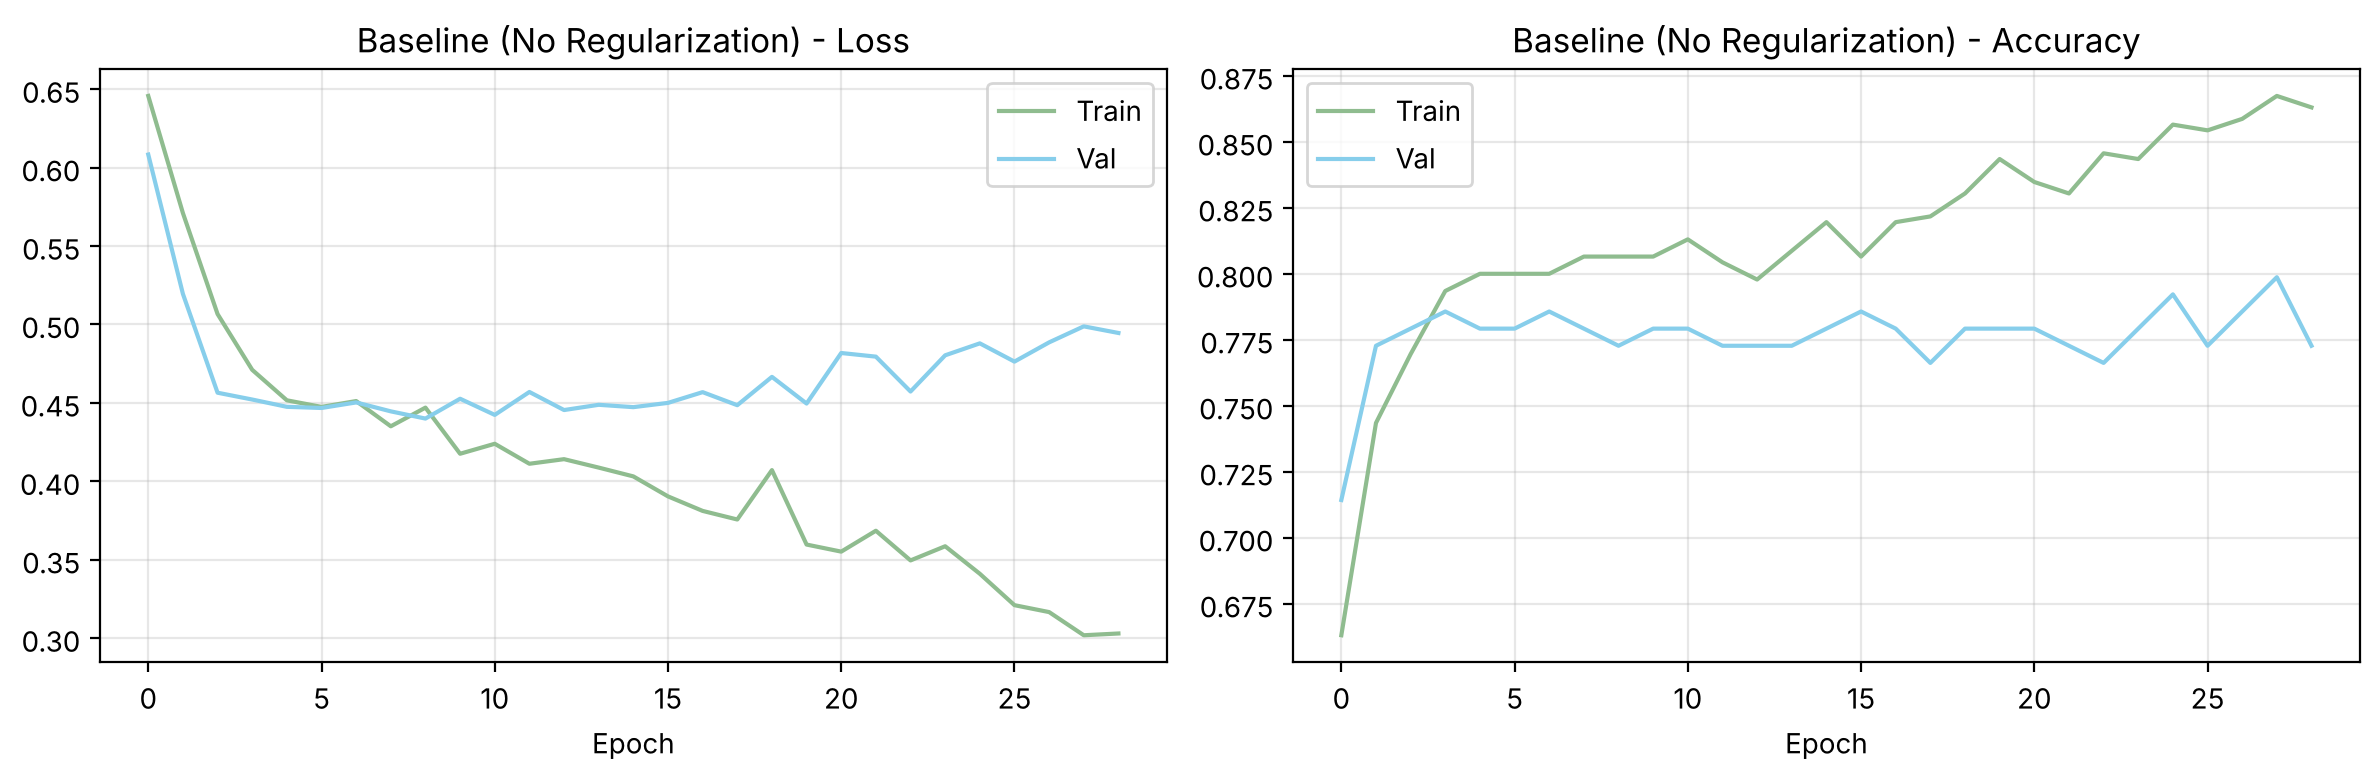

In [6]:
# 정규화 없는 기본 모델
class BaselineMLP(nn.Module):                     # 정규화 기법이 하나도 없는 기준 모델
    def __init__(self):
        super().__init__()                        # 부모 초기화
        self.model = nn.Sequential(               # 8 → 128 → 64 → 32 → 1 (데이터 768개에 비해 꽤 큰 모델)
            nn.Linear(8, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
            nn.Sigmoid()                          # 확률 출력
        )
    def forward(self, x):                         # 순전파
        return self.model(x)

print("=" * 50)
print("Baseline 모델 (정규화 없음)")
print("=" * 50)

torch.manual_seed(42)                             # [추가] 재현성을 위해 시드 고정
baseline = BaselineMLP()                          # 모델 생성
optimizer = optim.Adam(baseline.parameters(), lr=0.001)  # Adam, 학습률 0.001
criterion = nn.BCELoss()                          # 이진 교차 엔트로피

baseline, baseline_history = train_model(         # 최대 100에폭, 20에폭 연속 개선 없으면 중단
    baseline, train_loader, val_loader, criterion, optimizer,
    num_epochs=100, patience=20, device=device
)

baseline_metrics = evaluate_model(baseline, test_loader, device)  # 테스트 성능 측정
print(f"\nTest Accuracy: {baseline_metrics['accuracy']:.4f}, F1: {baseline_metrics['f1']:.4f}")

plot_history(baseline_history, "Baseline (No Regularization)")    # 학습 곡선

---

## Part 2: 정규화 기법 비교

Dropout, Weight Decay, Batch Normalization을 적용하고 비교합니다.

In [7]:
# ============================================
# 정규화 적용 모델
# ============================================

class RegularizedMLP(nn.Module):                          # 옵션에 따라 BatchNorm/Dropout을 끼워 넣는 모델
    def __init__(self, dropout_rate=0.0, use_batchnorm=False):
        super().__init__()                                # 부모 초기화

        layers = []                                       # 층을 차례로 담을 리스트

        # Layer 1
        layers.append(nn.Linear(8, 128))                  # 선형 변환 8 → 128
        if use_batchnorm:                                 # BatchNorm 옵션이 켜져 있으면
            layers.append(nn.BatchNorm1d(128))            # 128개 출력을 배치 단위로 평균 0·분산 1로 정규화
        layers.append(nn.ReLU())                          # 활성화
        if dropout_rate > 0:                              # Dropout 비율이 0보다 크면
            layers.append(nn.Dropout(dropout_rate))       # 학습 때 뉴런 일부를 무작위로 끔

        # Layer 2
        layers.append(nn.Linear(128, 64))                 # 128 → 64
        if use_batchnorm:
            layers.append(nn.BatchNorm1d(64))
        layers.append(nn.ReLU())
        if dropout_rate > 0:
            layers.append(nn.Dropout(dropout_rate))

        # Layer 3
        layers.append(nn.Linear(64, 32))                  # 64 → 32
        if use_batchnorm:
            layers.append(nn.BatchNorm1d(32))
        layers.append(nn.ReLU())
        if dropout_rate > 0:
            layers.append(nn.Dropout(dropout_rate))

        # Output
        layers.append(nn.Linear(32, 1))                   # 32 → 1
        layers.append(nn.Sigmoid())                       # 확률 출력

        self.model = nn.Sequential(*layers)               # 리스트를 풀어서(*) 순서대로 연결

    def forward(self, x):                                 # 순전파
        return self.model(x)

In [8]:
# 정규화 기법 비교 실험
configs = {                                                                   # 실험 설정 5가지
    'Baseline': {'dropout': 0.0, 'batchnorm': False, 'weight_decay': 0},      # 아무것도 없음
    'Dropout 0.3': {'dropout': 0.3, 'batchnorm': False, 'weight_decay': 0},   # 뉴런 30%를 무작위로 끔
    'Weight Decay': {'dropout': 0.0, 'batchnorm': False, 'weight_decay': 0.01},  # 큰 가중치에 벌점(L2)
    'BatchNorm': {'dropout': 0.0, 'batchnorm': True, 'weight_decay': 0},      # 층 입력을 정규화
    'All Combined': {'dropout': 0.3, 'batchnorm': True, 'weight_decay': 0.001},  # 세 가지 모두
}

results = {}                                                     # 실험별 결과 저장

for name, cfg in configs.items():                                # 설정을 하나씩 꺼내
    print(f"\n{'='*40}")
    print(f"{name}")
    print("="*40)

    torch.manual_seed(42)  # [추가] 모든 설정이 같은 초기 가중치·배치 순서로 출발 → 차이는 정규화 기법 때문만 남음
    model = RegularizedMLP(dropout_rate=cfg['dropout'], use_batchnorm=cfg['batchnorm'])  # 설정대로 모델 생성
    optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=cfg['weight_decay'])  # weight_decay = L2 정규화 세기
    criterion = nn.BCELoss()                                     # 손실 함수

    model, history = train_model(                                # 학습 (patience 15)
        model, train_loader, val_loader, criterion, optimizer,
        num_epochs=100, patience=15, device=device
    )

    metrics = evaluate_model(model, test_loader, device)         # 테스트 평가
    results[name] = {'history': history, 'metrics': metrics}     # 결과 저장

    print(f"Test Acc: {metrics['accuracy']:.4f}, F1: {metrics['f1']:.4f}")  # 결과 출력


Baseline


Epoch [20/100] Train: 0.3597/0.8435 Val: 0.4496/0.7792
Early stopping at epoch 24
Test Acc: 0.7338, F1: 0.5859

Dropout 0.3


Epoch [20/100] Train: 0.4531/0.7891 Val: 0.4460/0.7792
Early stopping at epoch 30
Test Acc: 0.7273, F1: 0.5800

Weight Decay


Epoch [20/100] Train: 0.4283/0.8109 Val: 0.4436/0.7792
Early stopping at epoch 24
Test Acc: 0.7208, F1: 0.5657

BatchNorm


Early stopping at epoch 19
Test Acc: 0.7403, F1: 0.6000

All Combined


Epoch [20/100] Train: 0.4547/0.7826 Val: 0.4423/0.7662
Early stopping at epoch 25
Test Acc: 0.7208, F1: 0.5825


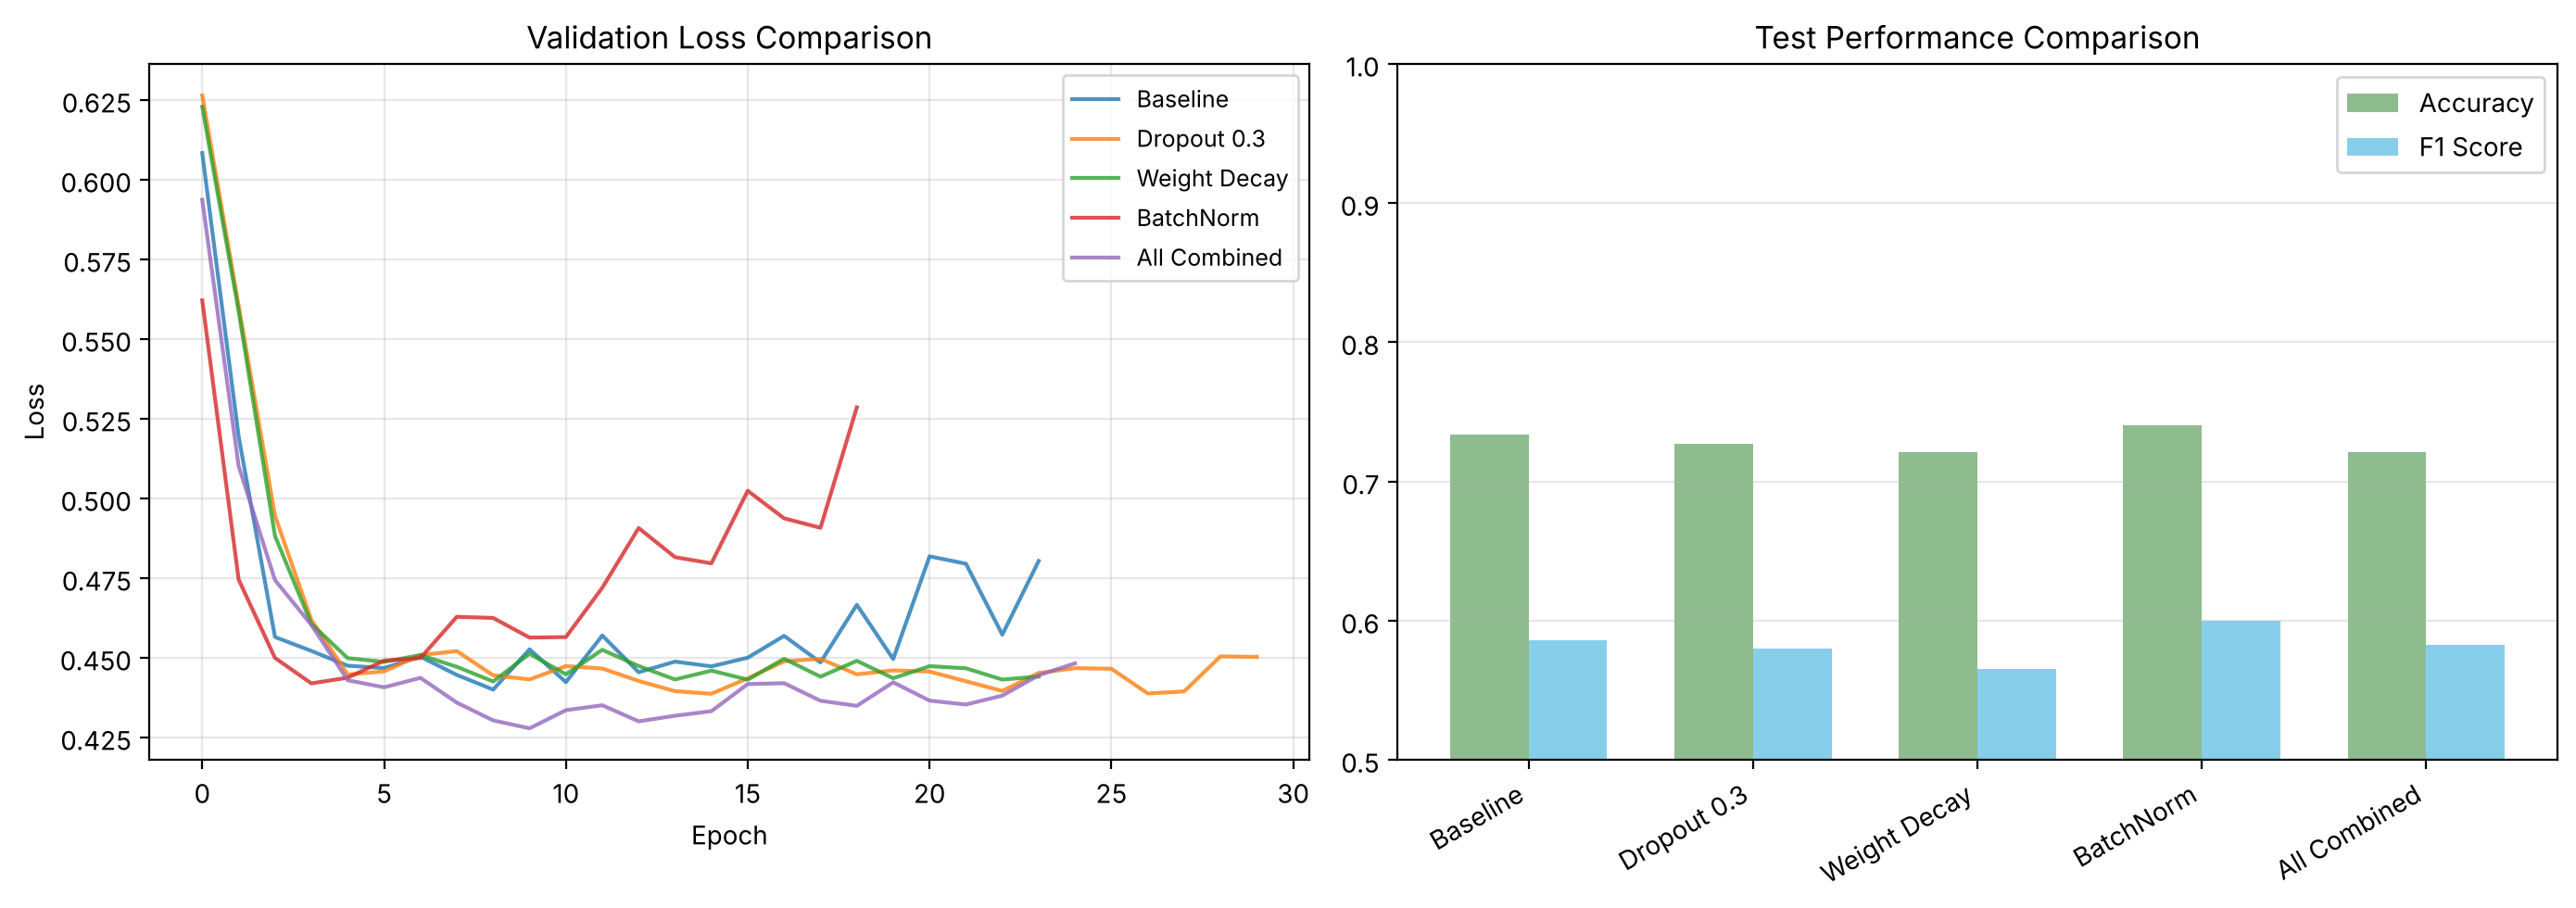


정규화 기법 성능 비교
기법                 |   Accuracy |   F1 Score
--------------------------------------------------
Baseline           |     0.7338 |     0.5859
Dropout 0.3        |     0.7273 |     0.5800
Weight Decay       |     0.7208 |     0.5657
BatchNorm          |     0.7403 |     0.6000
All Combined       |     0.7208 |     0.5825


In [9]:
# 결과 비교 시각화
fig, axes = plt.subplots(1, 2, figsize=(14, 5))                 # 왼쪽: 검증 손실, 오른쪽: 테스트 성능

# Validation Loss 비교
for name, result in results.items():                            # 실험별 검증 손실 곡선
    axes[0].plot(result['history']['val_loss'], label=name, alpha=0.8)
axes[0].set_title('Validation Loss Comparison')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)

# 성능 비교 바 차트
names = list(results.keys())                                    # 실험 이름 목록
accs = [results[n]['metrics']['accuracy'] for n in names]       # 정확도 목록
f1s = [results[n]['metrics']['f1'] for n in names]              # F1 목록

x = np.arange(len(names))                                       # 막대 위치 0, 1, 2, ...
width = 0.35                                                    # 막대 폭

axes[1].bar(x - width/2, accs, width, label='Accuracy', color='#8FBC8F')  # 정확도 막대 (왼쪽으로 반 칸)
axes[1].bar(x + width/2, f1s, width, label='F1 Score', color='#87CEEB')   # F1 막대 (오른쪽으로 반 칸)
axes[1].set_title('Test Performance Comparison')
axes[1].set_xticks(x)
axes[1].set_xticklabels(names, rotation=30, ha='right')         # 이름을 비스듬히
axes[1].set_ylim(0.5, 1.0)                                      # 차이가 잘 보이게 y축 범위 제한
axes[1].legend()
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

# 결과 표
print("\n" + "=" * 50)
print("정규화 기법 성능 비교")
print("=" * 50)
print(f"{'기법':<18} | {'Accuracy':>10} | {'F1 Score':>10}")
print("-" * 50)
for name, result in results.items():                            # 실험별 수치 출력
    m = result['metrics']
    print(f"{name:<18} | {m['accuracy']:>10.4f} | {m['f1']:>10.4f}")

### 🔍 학습 곡선 수치로 읽기: 과적합이 얼마나 생겼나?

과적합(overfitting, 학습 데이터만 외워서 새 데이터에 약해지는 현상)은 **학습 손실은 계속 내려가는데 검증 손실은 바닥을 찍고 다시 올라가는** 모습으로 나타납니다. 실험별로 ① 검증 손실이 가장 낮았던 에폭, ② 그 뒤로 검증 손실이 얼마나 다시 올랐는지, ③ 마지막 에폭의 학습–검증 손실 차이를 비교합니다.

기법             |   학습 에폭 |   최저 Val Loss(에폭) |  마지막 Val Loss |     반등폭 |  마지막 Train Loss |  Val-Train 차이
----------------------------------------------------------------------------------------------------------------
Baseline       |      24 |    0.4400 ( 9에폭) |        0.4803 | +0.0403 |          0.3586 |       +0.1217
Dropout 0.3    |      30 |    0.4387 (15에폭) |        0.4503 | +0.0116 |          0.4470 |       +0.0033
Weight Decay   |      24 |    0.4425 ( 9에폭) |        0.4441 | +0.0016 |          0.4324 |       +0.0117
BatchNorm      |      19 |    0.4420 ( 4에폭) |        0.5286 | +0.0866 |          0.3415 |       +0.1871
All Combined   |      25 |    0.4279 (10에폭) |        0.4482 | +0.0204 |          0.4070 |       +0.0412


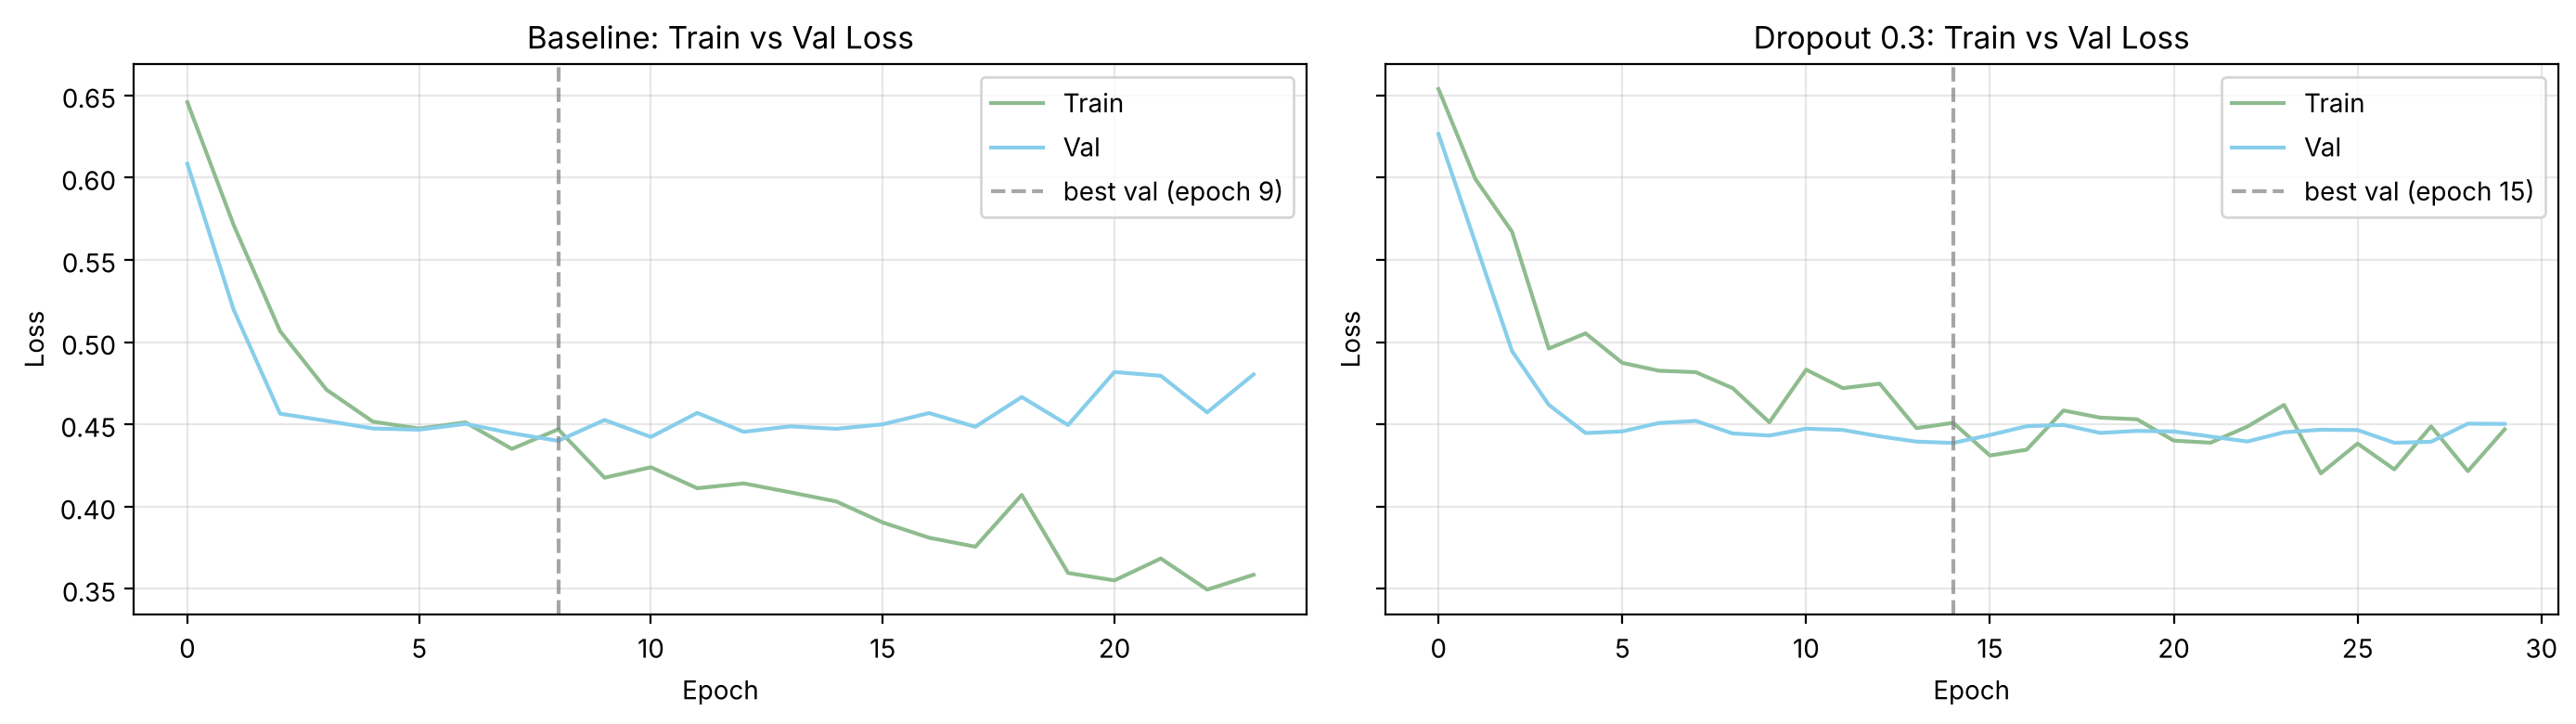

In [10]:
print(f"{'기법':<14} | {'학습 에폭':>7} | {'최저 Val Loss(에폭)':>17} | {'마지막 Val Loss':>13} | {'반등폭':>7} | {'마지막 Train Loss':>15} | {'Val-Train 차이':>13}")
print("-" * 112)
for name, result in results.items():                       # 실험별로
    h = result['history']                                  # 기록 꺼내기
    best_e = int(np.argmin(h['val_loss']))                 # 검증 손실 최저 에폭(0부터)
    rebound = h['val_loss'][-1] - h['val_loss'][best_e]    # 최저점 대비 마지막 검증 손실이 얼마나 올랐는지
    gap = h['val_loss'][-1] - h['train_loss'][-1]          # 마지막 에폭의 검증-학습 손실 차이(클수록 과적합 신호)
    print(f"{name:<14} | {len(h['val_loss']):>7} | {h['val_loss'][best_e]:>9.4f} ({best_e + 1:>2}에폭) | "
          f"{h['val_loss'][-1]:>13.4f} | {rebound:>+7.4f} | {h['train_loss'][-1]:>15.4f} | {gap:>+13.4f}")

# Baseline vs Dropout 학습 곡선 나란히 보기
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)   # 같은 y축으로 비교
for ax, name in zip(axes, ['Baseline', 'Dropout 0.3']):        # 두 실험만 골라서
    h = results[name]['history']
    ax.plot(h['train_loss'], label='Train', color='#8FBC8F')   # 학습 손실
    ax.plot(h['val_loss'], label='Val', color='#87CEEB')       # 검증 손실
    best_e = int(np.argmin(h['val_loss']))                     # 검증 최저 에폭
    ax.axvline(best_e, color='gray', linestyle='--', alpha=0.7, label=f'best val (epoch {best_e + 1})')  # 최저점 표시
    ax.set_title(f'{name}: Train vs Val Loss'); ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
    ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### [필수] 과제 2-1: 정규화 기법 분석

위 실험 결과를 보고 답하세요:

1. 어떤 정규화 기법이 가장 좋은 성능을 보였나요?
   - 답변: 테스트 성능 기준으로는 **BatchNorm**이 가장 좋았습니다(Accuracy 0.7403, F1 0.6000 → 템플릿의 선택 기준인 F1 1위). 다만 두 가지를 함께 봐야 합니다.
   - ① **차이가 아주 작습니다.** 테스트는 154명이라 BatchNorm(0.7403)과 Baseline(0.7338)의 정확도 차이는 **1명**입니다.
   - ② BatchNorm은 검증 손실이 **4에폭**에 바닥(0.4420)을 찍은 뒤 가장 크게 다시 올라(+0.0866) **과적합이 가장 빨리 진행된** 모델이었고, Early Stopping이 4에폭 시점의 가중치로 되돌려 놓았기 때문에 좋은 점수가 나온 것입니다.
   - 모델 선택의 원칙대로 **검증 세트**(최저 Val Loss)로 고르면 **All Combined**(0.4279)가 1위이고, 과적합 억제(마지막 Val–Train 손실 차이) 측면에서는 **Dropout**(+0.0033)과 **Weight Decay**(+0.0117)가 가장 효과적이었습니다(Baseline +0.1217, BatchNorm +0.1871).
   - 정리하면, 이 작은 데이터에서는 '어떤 기법이 압도적으로 좋다'기보다 **정규화가 과적합 진행을 늦추고 검증 손실을 안정시키는 효과**가 더 뚜렷하게 보였습니다.

2. Dropout이 과적합 방지에 어떻게 도움이 되나요? (학습 곡선 참고)
   - 답변: Dropout은 학습할 때마다 뉴런의 30%를 무작위로 꺼서, 모델이 특정 뉴런 몇 개에 의존해 학습 데이터를 통째로 외우는 것을 막습니다(매번 조금씩 다른 작은 모델을 학습시켜 평균 내는 **앙상블 효과**). 학습 곡선에서 그 효과가 보입니다.
   - **Baseline**: 검증 손실이 **9에폭**(0.4400)에 바닥을 찍은 뒤 학습 손실만 계속 내려가, 마지막에는 Train 0.3586 vs Val 0.4803으로 벌어졌습니다(차이 +0.1217, 최저점 대비 반등 +0.0403).
   - **Dropout 0.3**: 검증 손실 최저점이 **15에폭**(0.4387)으로 늦춰졌고, 마지막에도 Train 0.4470 vs Val 0.4503으로 두 곡선이 거의 붙어 있었습니다(차이 +0.0033, 반등 +0.0116).
   - 즉 Dropout은 **과적합이 시작되는 시점을 늦추고 학습–검증 차이를 줄여** 줍니다. (참고: Dropout 모델의 학습 손실은 뉴런을 끈 상태로 계산되기 때문에 원래 조금 높게 나옵니다. 평가할 때 `model.eval()`을 부르면 Dropout이 꺼지고 모든 뉴런을 씁니다 → 2일차의 "왜 eval()을 하지?"에 대한 답입니다.)
   - 💡 비유: 팀 과제를 할 때 매번 무작위로 몇 명을 빼고 연습하면, 에이스 한 명에게만 기대지 않고 모두가 골고루 실력을 키우게 되는 것과 같아요.

---

## Part 3: 최종 모델 평가

최고 성능 모델: BatchNorm


Epoch [20/100] Train: 0.3164/0.8739 Val: 0.5170/0.7532
Early stopping at epoch 24


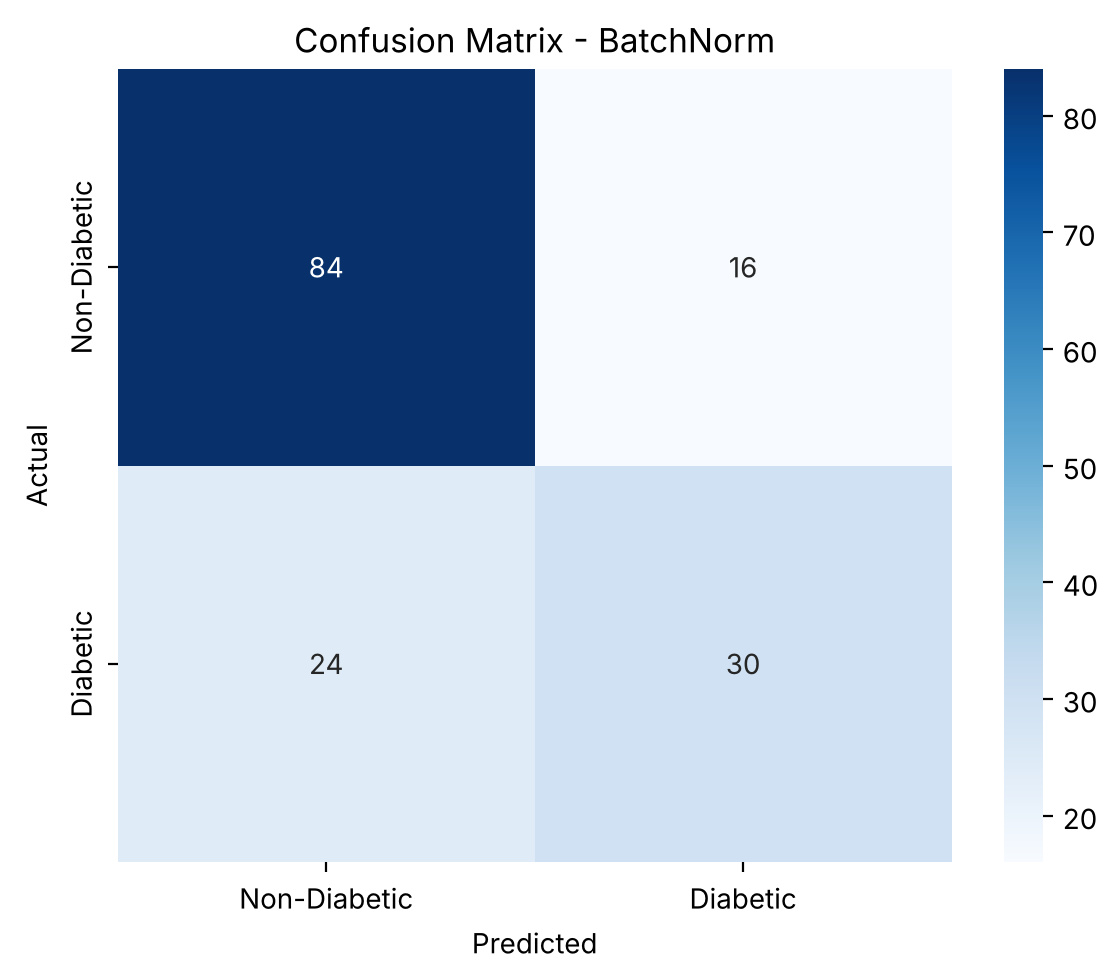


최종 성능: Accuracy=0.7403, F1=0.6000
혼동 행렬 [[TN, FP], [FN, TP]] = [[84, 16], [24, 30]]


In [11]:
# 최고 성능 모델 선택 및 상세 평가
best_name = max(results.items(), key=lambda x: x[1]['metrics']['f1'])[0]   # F1이 가장 높은 실험 이름
print(f"최고 성능 모델: {best_name}")

# 최종 모델 다시 학습
best_cfg = configs[best_name]                               # 그 실험의 설정 꺼내기
torch.manual_seed(42)                                       # [추가] 재현성을 위해 시드 고정
final_model = RegularizedMLP(
    dropout_rate=best_cfg['dropout'],
    use_batchnorm=best_cfg['batchnorm']
)                                                           # 같은 설정으로 새 모델
optimizer = optim.Adam(final_model.parameters(), lr=0.001, weight_decay=best_cfg['weight_decay'])
criterion = nn.BCELoss()

final_model, final_history = train_model(                   # patience를 20으로 조금 넉넉하게
    final_model, train_loader, val_loader, criterion, optimizer,
    num_epochs=100, patience=20, device=device
)

# 혼동 행렬
final_model.eval()                                          # 평가 모드
all_preds, all_labels = [], []                              # 예측·정답 모으기
with torch.no_grad():                                       # 기울기 끄기
    for X_batch, y_batch in test_loader:                    # 테스트 배치 반복
        X_batch = X_batch.to(device)
        outputs = final_model(X_batch)                      # 예측 확률
        preds = (outputs > 0.5).float().cpu()               # 0/1 예측
        all_preds.extend(preds.numpy().flatten())           # 예측 모으기
        all_labels.extend(y_batch.numpy().flatten())        # 정답 모으기

cm = confusion_matrix(all_labels, all_preds)                # 2x2 표: [실제 0/1] x [예측 0/1]

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',          # 칸마다 숫자(정수) 표시
            xticklabels=['Non-Diabetic', 'Diabetic'],
            yticklabels=['Non-Diabetic', 'Diabetic'])
plt.title(f'Confusion Matrix - {best_name}')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

final_metrics = evaluate_model(final_model, test_loader, device)   # 최종 성능
print(f"\n최종 성능: Accuracy={final_metrics['accuracy']:.4f}, F1={final_metrics['f1']:.4f}")
print(f"혼동 행렬 [[TN, FP], [FN, TP]] = {cm.tolist()}")             # 숫자로도 확인

### 🔍 추가 분석: 판정 기준(threshold)을 낮추면 놓치는 환자가 줄어들까?

의료 선별검사에서는 **당뇨 환자를 '정상'으로 놓치는 것(FN, 거짓 음성)**이 더 위험한 경우가 많습니다. 모델은 확률을 내놓고 우리는 보통 0.5를 기준으로 자르는데, 이 기준을 낮추면 어떻게 되는지 확인합니다.
⚠️ 기준값은 **검증 세트**로 정해야 공정합니다. 테스트 세트는 마지막 '성적표'라서, 테스트를 보면서 기준을 고르면 성적을 부풀리게 됩니다.

In [12]:
final_model.eval()                                                      # 평가 모드
with torch.no_grad():                                                   # 기울기 끄기
    val_probs = final_model(X_val_t.to(device)).cpu().numpy().flatten() # 검증 세트 154명의 '당뇨일 확률'

print(f"{'기준':>5} | {'TN':>3} {'FP':>3} {'FN':>3} {'TP':>3} | {'재현율(놓치지 않은 비율)':>14} | {'정밀도(양성 판정 중 진짜)':>15} | {'F1':>6}")
print("-" * 86)
for th in [0.5, 0.4, 0.3]:                                              # 기준을 0.5 → 0.4 → 0.3으로 낮춰 보기
    pred = (val_probs > th).astype(int)                                 # 확률이 기준보다 크면 1(당뇨)로 판정
    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()              # 2x2 표를 4개 숫자로 펼치기
    recall = tp / (tp + fn)                                             # 실제 당뇨 중 잡아낸 비율
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0                # 당뇨라고 판정한 사람 중 진짜 당뇨 비율
    print(f"{th:>5} | {tn:>3} {fp:>3} {fn:>3} {tp:>3} | {recall:>22.4f} | {precision:>22.4f} | {f1_score(y_val, pred):>6.4f}")

   기준 |  TN  FP  FN  TP | 재현율(놓치지 않은 비율) | 정밀도(양성 판정 중 진짜) |     F1
--------------------------------------------------------------------------------------
  0.5 |  89  11  21  33 |                 0.6111 |                 0.7500 | 0.6735


  0.4 |  80  20  16  38 |                 0.7037 |                 0.6552 | 0.6786
  0.3 |  66  34   6  48 |                 0.8889 |                 0.5854 | 0.7059


#### 📝 최종 모델 결과 해석

- F1 기준 최고 모델인 **BatchNorm**을 다시 학습한 결과, 테스트 성능은 Accuracy **0.7403**, F1 **0.6000**으로 Part 2 비교 실험 때와 같았습니다. 같은 시드로 출발하고, 버그를 고친 '최적 가중치 복원' 덕분에 똑같이 4에폭 시점의 가중치로 돌아오기 때문입니다(patience만 15 → 20으로 달라서 멈춘 에폭만 다름).
- 혼동 행렬 `[[84, 16], [24, 30]]`: 비당뇨 100명 중 84명을 맞혔지만(특이도 0.84), **당뇨 환자 54명 중 24명을 '정상'으로 놓쳤습니다**(재현율 30/54 ≈ 0.56).
- 검증 세트에서 판정 기준을 0.5 → 0.3으로 낮추자 놓친 환자(FN)가 21명 → 6명, 재현율이 0.6111 → 0.8889로 크게 좋아졌고, 대신 정밀도는 0.7500 → 0.5854로 떨어졌습니다(정상인을 당뇨로 오판한 FP 11명 → 34명).
- 선별검사처럼 '놓치지 않는 것'이 중요하면 기준을 낮추고, '오진을 줄이는 것'이 중요하면 기준을 높이는 식으로 **목적에 맞게 기준을 정하는 것**이 정확도 숫자 하나보다 중요합니다.

---

## 3일차 학습 정리 체크리스트

아래 항목을 체크하세요:

- [x] 과적합 현상 이해: Train 손실은 감소하지만 Val 손실은 증가
- [x] Dropout: 학습 시 랜덤하게 뉴런을 비활성화
- [x] Weight Decay (L2): 가중치가 너무 커지는 것을 방지
- [x] Batch Normalization: 각 층의 입력을 정규화하여 학습 안정화
- [x] Early Stopping: 검증 손실이 개선되지 않으면 학습 조기 종료

---

## 수고하셨습니다!

### 제출 전 체크리스트
- [x] 과제 2-1 (정규화 기법 분석) 답변 작성
- [x] 모든 셀 실행 완료

## 📌 핵심 정리

- **과적합 신호** = 학습 손실은 계속 내려가는데 검증 손실은 바닥을 찍고 다시 올라가는 것. Baseline은 9에폭 이후 반등해 마지막 Val–Train 차이가 +0.1217까지 벌어졌습니다.
- **Dropout**(뉴런 무작위 끄기)과 **Weight Decay**(큰 가중치에 벌점, L2)는 그 차이를 +0.0033, +0.0117로 크게 줄였습니다. **BatchNorm**은 학습은 빨랐지만(4에폭에 최저) 이 작은 데이터에서는 과적합도 가장 빨랐습니다.
- **Early Stopping**은 '멈추기'뿐 아니라 **최적 시점 가중치 복원**까지 해야 완성입니다. `state_dict()`는 반드시 `copy.deepcopy`로 저장해야 합니다(얕은 복사는 이후 학습으로 값이 같이 바뀜).
- 테스트 154명에서 정확도 0.0065 차이는 **1명**입니다. 작은 차이로 우열을 단정하지 말고, 모델·판정 기준 선택은 **검증 세트**로, 테스트는 마지막에 한 번만 봅니다.
- 의료 데이터에서는 정확도 하나보다 **재현율·정밀도·F1**과 **판정 기준(threshold)**을 목적에 맞게 함께 봐야 합니다.